# Aprendizaje no supervisado: modelado y análisis de clusters

En la notebook anterior construimos una tabla con un perfil por pozo. Cada fila representa un pozo y las columnas resumen su comportamiento productivo, su historial y algunas características físicas.

En esta notebook aplicaremos un modelo de clustering para identificar grupos de pozos con perfiles similares.

El algoritmo principal será DBSCAN, ya que permite encontrar grupos basados en densidad y detectar pozos atípicos como ruido. Antes de aplicarlo, transformaremos y escalaremos las variables para que las diferencias de magnitud no distorsionen las distancias.

### Importación de librerías

Importamos las librerías necesarias para cargar los perfiles, transformar las variables, calcular distancias, aplicar DBSCAN y evaluar los agrupamientos obtenidos.

In [41]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")

sns.set_theme(style="whitegrid")

## 1. Carga y revisión de los perfiles

Cargamos la tabla generada en la notebook anterior. Cada fila representa un pozo y las columnas contienen variables agregadas que resumen su comportamiento histórico, productivo y físico.

En esta etapa verificamos que el archivo se haya generado correctamente y que no existan duplicados ni valores faltantes en las variables que utilizaremos inicialmente.

In [25]:
RUTA_PROCESSED = Path("..") / "data" / "processed"
RUTA_PERFILES = RUTA_PROCESSED / "perfiles_pozos_clustering.csv"

perfiles_pozos = pd.read_csv(
    RUTA_PERFILES,
    parse_dates=["primer_registro", "ultimo_registro"],
    low_memory=False,
)

print(f"Filas: {len(perfiles_pozos):,}")
print(f"Columnas: {perfiles_pozos.shape[1]}")
print(f"Pozos únicos: {perfiles_pozos['idpozo'].nunique():,}")

display(perfiles_pozos.head())

Filas: 4,839
Columnas: 29
Pozos únicos: 4,839


,idpozo,sigla,meses_observados,primer_registro,ultimo_registro,produccion_media,produccion_mediana,produccion_maxima,produccion_acumulada,desvio_produccion,meses_productivos,porcentaje_meses_productivos,produccion_ultimo_mes,produccion_media_3m,produccion_media_6m,cambio_reciente,meses_desde_inicio,profundidad,cota,tef,tipoestado,tipoextraccion,tipopozo,empresa,cuenca,provincia,formacion,sub_tipo_recurso,tipo_terminacion_ultima
0,3640,PPC.Nq.EC-4,246,2006-02-01,2026-07-01,60.072,51.637,164.532,"14,777.817",34.723,241,97.967,0.001,15.776,21.609,-5.832,245,"2,585.000",555.600,0.002,Extracción Efectiva,Bombeo Mecánico,Petrolífero,TANGO ENERGY ARGENTINA S.A.,NEUQUINA,Neuquén,VACA MUERTA,SHALE,NaN
1,8043,YPF.Nq.FP.x-2,246,2006-01-01,2026-07-01,1.967,0.000,82.930,483.900,10.109,15,6.098,0.000,0.000,0.000,0.000,246,"3,243.000",463.400,0.000,Parado Transitoriamente,Sin Sistema de Extracción,Gasífero,TECPETROL S.A.,NEUQUINA,Neuquén,VACA MUERTA,SHALE,NaN
2,10073,CSJ.RN.LMa.a-3,247,2006-01-01,2026-07-01,25.759,19.560,328.000,"6,362.390",27.217,242,97.976,22.330,22.050,21.800,0.250,246,"3,850.000",456.300,31.000,Extracción Efectiva,Surgencia Natural,Petrolífero,CAPEX S.A.,NEUQUINA,Rio Negro,LAJAS,TIGHT,NaN
3,11191,Q.SC.ACI-21,247,2006-01-01,2026-07-01,5.825,3.820,62.772,"1,438.707",6.868,224,90.688,6.753,2.897,1.889,1.007,246,"3,186.000",311.990,26.167,Extracción Efectiva,Plunger Lift,Gasífero,COMPAÑÍA GENERAL DE COMBUSTIBLES S.A.,AUSTRAL,Santa Cruz,MAGALLANES,TIGHT,Punzado
4,11641,TPT.Nq.PS-1001,246,2006-01-01,2026-07-01,3.453,2.632,13.793,849.321,2.561,243,98.780,2.883,2.642,2.655,-0.013,246,"3,250.000",593.400,31.000,Extracción Efectiva,Surgencia Natural,Gasífero,TECPETROL S.A.,NEUQUINA,Neuquén,LAJAS,TIGHT,NaN


In [26]:
print("Valores faltantes por columna")
display(
    perfiles_pozos.isna()
    .sum()
    .loc[lambda serie: serie > 0]
    .to_frame("valores_faltantes")
)

print("Identificadores duplicados")
print(perfiles_pozos["idpozo"].duplicated().sum())

Valores faltantes por columna


,valores_faltantes
tipo_terminacion_ultima,1162


Identificadores duplicados
0


## 2. Selección de variables para el modelo

Para calcular las similitudes entre los pozos utilizaremos las variables numéricas construidas en la notebook anterior.

No ingresan al modelo:

- `idpozo` y `sigla`, porque son identificadores;
- `primer_registro` y `ultimo_registro`, porque son fechas;
- las variables categóricas, como cuenca, provincia, formación y empresa;
- `tipo_terminacion_ultima`, porque presenta valores faltantes y se reservará para interpretar los grupos.

Las variables categóricas se conservarán en `perfiles_pozos` para analizarlas después de obtener los clusters.

In [27]:
variables_clustering = [
    "meses_observados",
    "produccion_media",
    "produccion_mediana",
    "produccion_maxima",
    "produccion_acumulada",
    "desvio_produccion",
    "meses_productivos",
    "porcentaje_meses_productivos",
    "produccion_ultimo_mes",
    "produccion_media_3m",
    "produccion_media_6m",
    "cambio_reciente",
    "meses_desde_inicio",
    "profundidad",
    "cota",
    "tef",
]

identificadores = perfiles_pozos[
    ["idpozo", "sigla"]
].copy()

X_clustering = perfiles_pozos[
    variables_clustering
].copy()

print(f"Perfiles utilizados: {X_clustering.shape[0]:,}")
print(f"Variables utilizadas: {X_clustering.shape[1]}")
print(f"Valores faltantes: {X_clustering.isna().sum().sum():,}")

display(
    pd.DataFrame(
        {
            "variable": X_clustering.columns,
            "tipo": X_clustering.dtypes.astype(str),
            "faltantes": X_clustering.isna().sum().values,
        }
    )
)

Perfiles utilizados: 4,839
Variables utilizadas: 16
Valores faltantes: 0


,variable,tipo,faltantes
meses_observados,meses_observados,int64,0
produccion_media,produccion_media,float64,0
produccion_mediana,produccion_mediana,float64,0
produccion_maxima,produccion_maxima,float64,0
produccion_acumulada,produccion_acumulada,float64,0
desvio_produccion,desvio_produccion,float64,0
meses_productivos,meses_productivos,int64,0
porcentaje_meses_productivos,porcentaje_meses_productivos,float64,0
produccion_ultimo_mes,produccion_ultimo_mes,float64,0
produccion_media_3m,produccion_media_3m,float64,0


## 3. Revisión de distribuciones y escalas

Antes de aplicar transformaciones y calcular distancias, revisamos las escalas y distribuciones de las variables seleccionadas.

Las variables productivas pueden presentar valores extremos y una fuerte asimetría. Si utilizáramos los valores originales, las variables con mayor magnitud podrían dominar la distancia entre los pozos.

Esta revisión nos permitirá decidir qué variables requieren una transformación logarítmica antes de la estandarización.

In [28]:
estadisticas_variables = (
    X_clustering
    .describe()
    .T
    .round(2)
)

display(estadisticas_variables)

,count,mean,std,min,25%,50%,75%,max
meses_observados,"4,839.000",86.860,56.840,6.000,36.000,85.000,128.000,247.000
produccion_media,"4,839.000",825.900,"1,244.250",0.000,5.240,93.490,"1,407.310","11,078.780"
produccion_mediana,"4,839.000",699.950,"1,194.240",0.000,0.000,44.680,"1,026.650","9,811.370"
produccion_maxima,"4,839.000","2,413.810","2,938.940",0.000,50.110,863.310,"4,635.080","26,593.260"
produccion_acumulada,"4,839.000","28,666.350","36,905.050",0.000,569.970,"10,545.840","49,534.120","343,442.200"
desvio_produccion,"4,839.000",592.400,784.800,0.000,8.900,140.340,"1,095.510","7,156.570"
meses_productivos,"4,839.000",56.230,49.420,0.000,14.000,43.000,90.000,247.000
porcentaje_meses_productivos,"4,839.000",71.760,37.220,0.000,49.690,92.980,100.000,100.000
produccion_ultimo_mes,"4,839.000",502.410,"1,026.620",0.000,0.000,15.680,580.280,"10,583.300"
produccion_media_3m,"4,839.000",530.530,"1,068.100",0.000,0.000,18.610,613.270,"10,601.250"


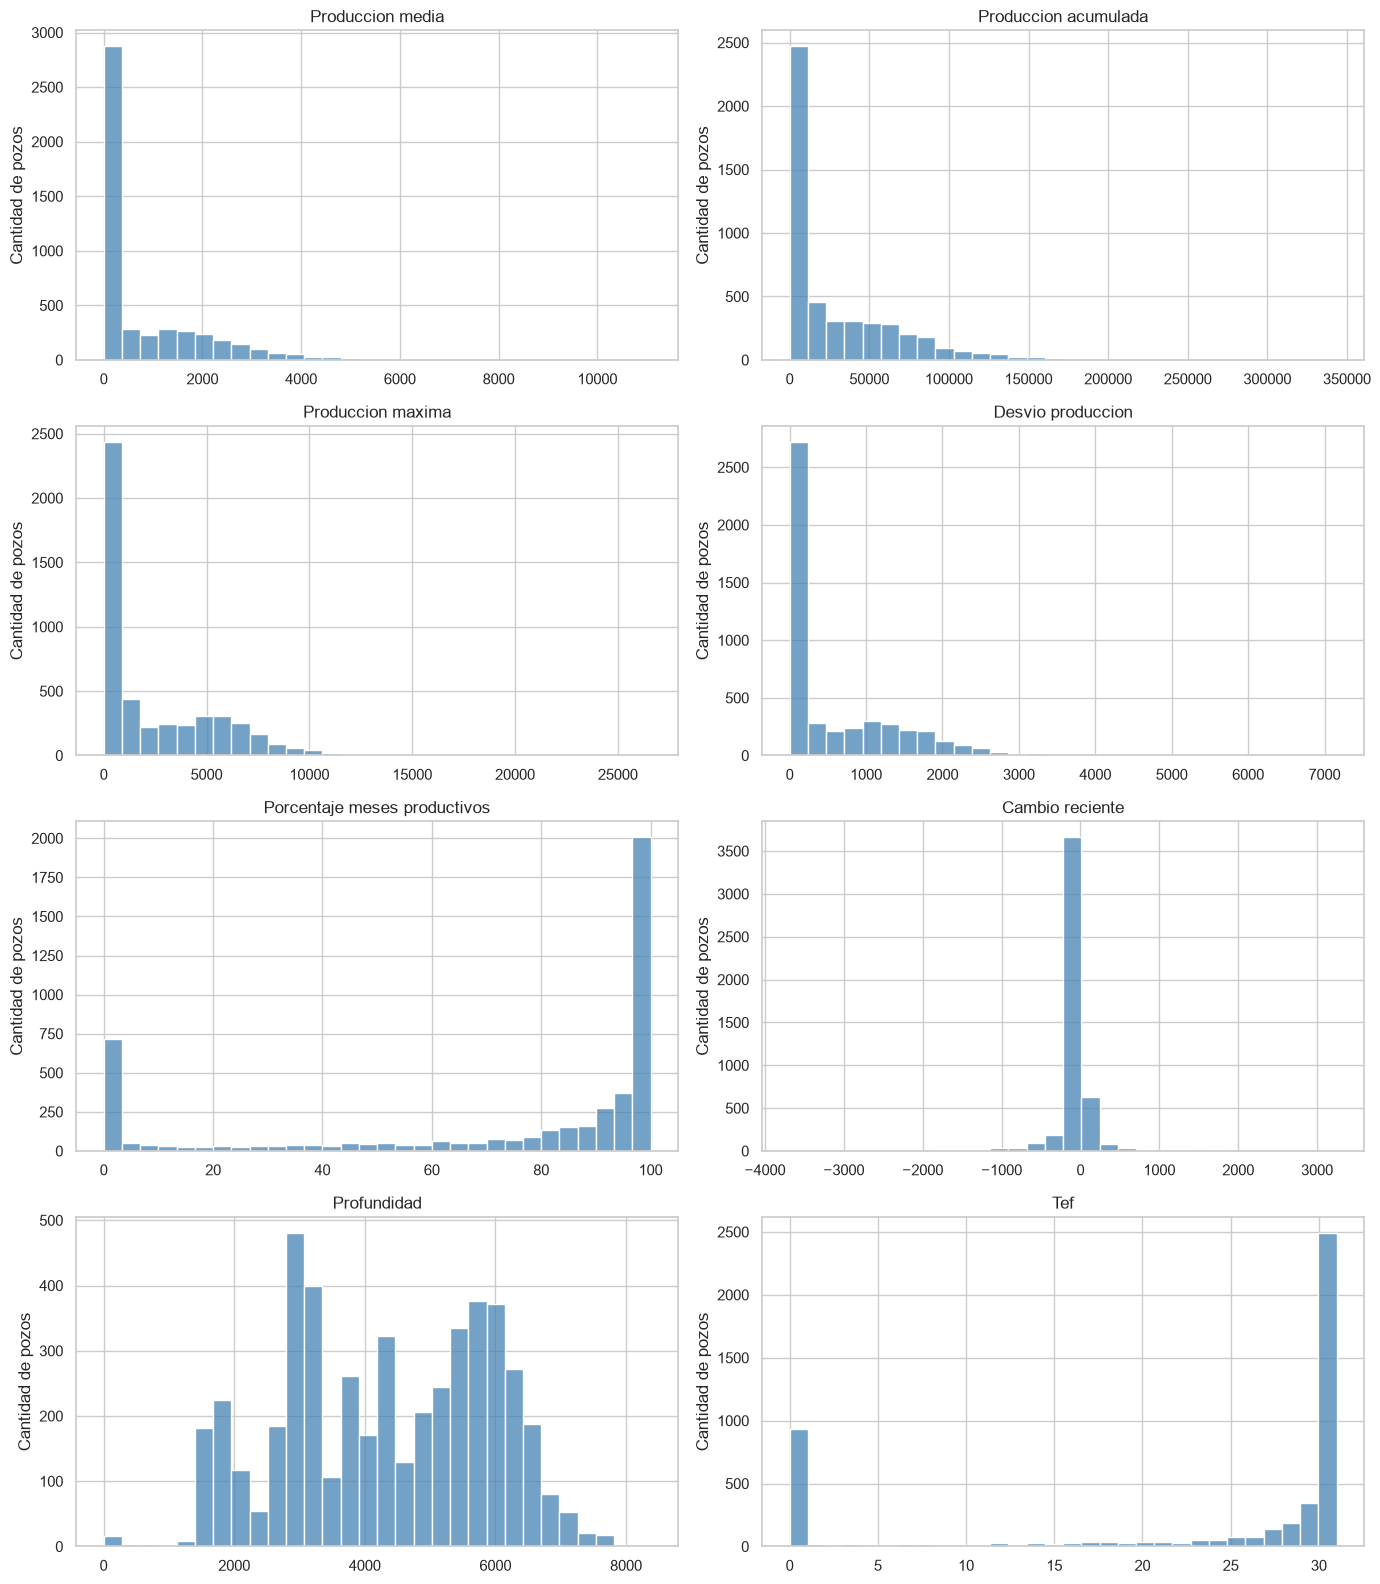

In [29]:
variables_graficar = [
    "produccion_media",
    "produccion_acumulada",
    "produccion_maxima",
    "desvio_produccion",
    "porcentaje_meses_productivos",
    "cambio_reciente",
    "profundidad",
    "tef",
]

fig, ejes = plt.subplots(4, 2, figsize=(14, 16))

for eje, variable in zip(ejes.flat, variables_graficar):
    sns.histplot(
        data=X_clustering,
        x=variable,
        bins=30,
        color="steelblue",
        ax=eje
    )
    eje.set_title(variable.replace("_", " ").capitalize())
    eje.set_xlabel("")
    eje.set_ylabel("Cantidad de pozos")

plt.tight_layout()
plt.show()

## 4. Transformación de variables

La revisión exploratoria mostró que varias variables productivas presentan una distribución asimétrica: muchos pozos tienen valores bajos y un grupo menor concentra valores muy elevados.

En un modelo basado en distancias, estos valores extremos podrían influir demasiado en la formación de los grupos. Por este motivo aplicamos una transformación logarítmica a las variables no negativas seleccionadas.

Utilizamos `log1p`, que calcula:

```text
log(1 + x)

In [30]:
variables_log = [
    "meses_observados",
    "produccion_media",
    "produccion_mediana",
    "produccion_maxima",
    "produccion_acumulada",
    "desvio_produccion",
    "meses_productivos",
    "produccion_ultimo_mes",
    "produccion_media_3m",
    "produccion_media_6m",
]

X_transformado = X_clustering.copy()

for variable in variables_log:
    X_transformado[variable] = np.log1p(
        X_transformado[variable]
    )

print("Variables transformadas con log1p:")
print(variables_log)

Variables transformadas con log1p:
['meses_observados', 'produccion_media', 'produccion_mediana', 'produccion_maxima', 'produccion_acumulada', 'desvio_produccion', 'meses_productivos', 'produccion_ultimo_mes', 'produccion_media_3m', 'produccion_media_6m']


La transformación se aplicó a las variables no negativas relacionadas principalmente con la cantidad de meses y el nivel de producción.

La variable `cambio_reciente` se mantiene en su escala original porque contiene valores positivos y negativos. Las variables restantes se conservarán temporalmente sin logaritmo y luego todas serán estandarizadas para que tengan una influencia comparable en el cálculo de distancias.

In [31]:
display(
    X_transformado[variables_log]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
meses_observados,"4,839.000",4.190,0.840,1.950,3.610,4.450,4.860,5.510
produccion_media,"4,839.000",4.430,2.880,0.000,1.830,4.550,7.250,9.310
produccion_mediana,"4,839.000",3.860,3.070,0.000,0.000,3.820,6.940,9.190
produccion_maxima,"4,839.000",5.800,3.020,0.000,3.930,6.760,8.440,10.190
produccion_acumulada,"4,839.000",7.910,3.740,0.000,6.350,9.260,10.810,12.750
desvio_produccion,"4,839.000",4.470,2.680,0.000,2.290,4.950,7.000,8.880
meses_productivos,"4,839.000",3.360,1.520,0.000,2.710,3.780,4.510,5.510
produccion_ultimo_mes,"4,839.000",3.310,3.010,0.000,0.000,2.810,6.370,9.270
produccion_media_3m,"4,839.000",3.400,3.020,0.000,0.000,2.980,6.420,9.270
produccion_media_6m,"4,839.000",3.460,3.020,0.000,0.000,3.040,6.460,9.310


## 5. Estandarización de las variables

Después de aplicar las transformaciones logarítmicas, estandarizamos todas las variables seleccionadas utilizando `StandardScaler`.

La estandarización transforma cada variable para que tenga:

- media cercana a 0;
- desvío estándar cercano a 1.

Este paso es necesario porque las variables todavía están expresadas en unidades diferentes. Por ejemplo, `profundidad` está expresada en metros, `porcentaje_meses_productivos` va de 0 a 100 y `tef` tiene valores entre 0 y 31.

Al estandarizar, ninguna variable tendrá una influencia mayor únicamente por utilizar números más grandes.

In [32]:
escalador = StandardScaler()

X_escalado_array = escalador.fit_transform(X_transformado)

X_escalado = pd.DataFrame(
    X_escalado_array,
    columns=X_transformado.columns,
    index=X_transformado.index,
)

display(
    X_escalado.describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
meses_observados,"4,839.000",-0.000,1.000,-2.680,-0.690,0.310,0.790,1.570
produccion_media,"4,839.000",-0.000,1.000,-1.540,-0.900,0.040,0.980,1.690
produccion_mediana,"4,839.000",0.000,1.000,-1.260,-1.260,-0.010,1.000,1.740
produccion_maxima,"4,839.000",-0.000,1.000,-1.920,-0.620,0.320,0.870,1.450
produccion_acumulada,"4,839.000",0.000,1.000,-2.120,-0.420,0.360,0.780,1.290
desvio_produccion,"4,839.000",-0.000,1.000,-1.670,-0.810,0.180,0.940,1.650
meses_productivos,"4,839.000",0.000,1.000,-2.210,-0.430,0.280,0.760,1.420
porcentaje_meses_productivos,"4,839.000",-0.000,1.000,-1.930,-0.590,0.570,0.760,0.760
produccion_ultimo_mes,"4,839.000",-0.000,1.000,-1.100,-1.100,-0.160,1.020,1.980
produccion_media_3m,"4,839.000",-0.000,1.000,-1.130,-1.130,-0.140,1.000,1.950


In [33]:
print(
    f"Mayor diferencia absoluta entre medias y 0: "
    f"{X_escalado.mean().abs().max():.10f}"
)

print(
    f"Mayor diferencia absoluta entre desvíos y 1: "
    f"{(X_escalado.std() - 1).abs().max():.10f}"
)

Mayor diferencia absoluta entre medias y 0: 0.0000000000
Mayor diferencia absoluta entre desvíos y 1: 0.0001033432


## 6. Selección de parámetros para DBSCAN

DBSCAN necesita dos parámetros principales:

- `min_samples`: cantidad mínima de observaciones necesarias para considerar que existe una zona densa;
- `eps`: radio máximo de vecindad entre observaciones.

El algoritmo no requiere definir previamente la cantidad de grupos. Esa es una de las razones por las que resulta apropiado para este análisis.

Como estamos trabajando con 16 variables, comenzaremos evaluando valores de `min_samples` relacionados con la cantidad de dimensiones del problema. Primero utilizaremos `min_samples=16` y luego podremos comparar su comportamiento con otras alternativas.

### 6.1. Curva de distancias de vecinos

Para obtener valores candidatos de `eps`, calculamos la distancia de cada pozo a su vecino número `k`, donde `k` coincide con `min_samples`.

Luego ordenamos esas distancias y las representamos gráficamente. El cambio de pendiente de la curva permite identificar un rango razonable de valores para el radio de vecindad.

In [34]:
MIN_SAMPLES_INICIAL = 16

vecinos = NearestNeighbors(
    n_neighbors=MIN_SAMPLES_INICIAL
)

vecinos.fit(X_escalado)

distancias_vecinos, indices_vecinos = vecinos.kneighbors(
    X_escalado
)

distancias_k = np.sort(
    distancias_vecinos[:, -1]
)

print(f"min_samples utilizado: {MIN_SAMPLES_INICIAL}")
print(f"Cantidad de distancias calculadas: {len(distancias_k):,}")
print(f"Distancia mínima: {distancias_k.min():.3f}")
print(f"Distancia mediana: {np.median(distancias_k):.3f}")
print(f"Distancia máxima: {distancias_k.max():.3f}")

min_samples utilizado: 16
Cantidad de distancias calculadas: 4,839
Distancia mínima: 0.134
Distancia mediana: 0.888
Distancia máxima: 8.553


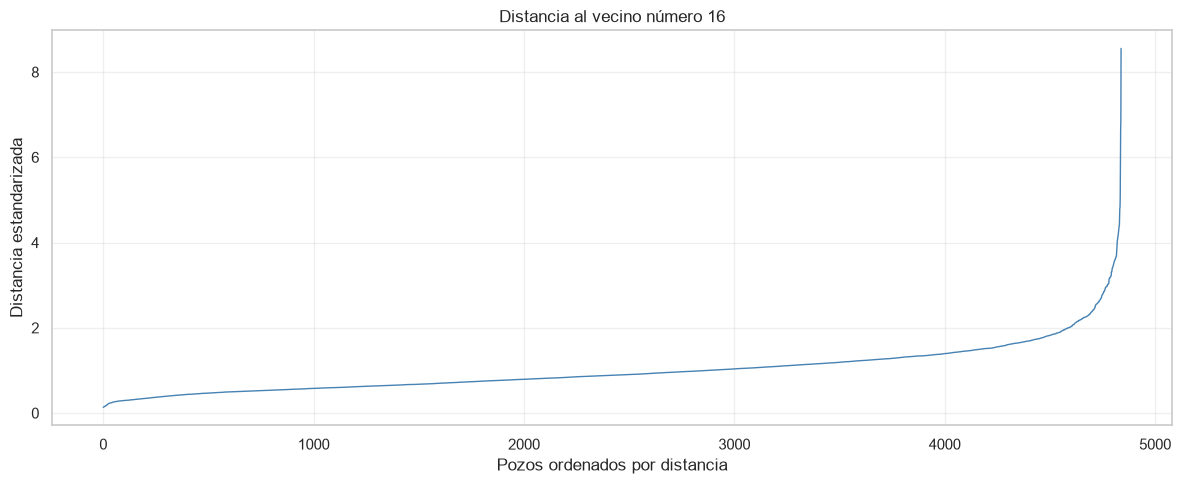

In [35]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    np.arange(len(distancias_k)),
    distancias_k,
    color="steelblue",
    linewidth=1
)

ax.set_title(
    f"Distancia al vecino número {MIN_SAMPLES_INICIAL}"
)
ax.set_xlabel("Pozos ordenados por distancia")
ax.set_ylabel("Distancia estandarizada")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 6.2. Comparación de configuraciones mediante una grilla

La curva de distancias permitió definir un rango inicial de valores para `eps`, pero no alcanza para seleccionar una configuración definitiva.

Por este motivo evaluamos distintas combinaciones de `eps` y `min_samples`. Para cada configuración calculamos:

- cantidad de grupos encontrados;
- porcentaje de pozos considerados ruido;
- tamaño del grupo más grande;
- tamaño del grupo más pequeño;
- silhouette;
- índice de Calinski-Harabasz;
- índice de Davies-Bouldin.

La silhouette, Calinski-Harabasz y Davies-Bouldin son métricas internas. Se calculan sobre los pozos asignados a un grupo y se excluyen los puntos marcados como ruido (`-1`).

Estas métricas no se interpretan de manera aislada. Una configuración puede obtener buenos valores internos dejando fuera una proporción excesiva de pozos. Por eso también revisamos el porcentaje de ruido, el tamaño de los grupos y la utilidad de la segmentación.

In [42]:
def metricas_dbscan(X, etiquetas):
    etiquetas = np.asarray(etiquetas)

    mascara_no_ruido = etiquetas != -1
    X_sin_ruido = X[mascara_no_ruido]
    etiquetas_sin_ruido = etiquetas[mascara_no_ruido]

    grupos = np.unique(etiquetas_sin_ruido)
    cantidad_grupos = len(grupos)

    porcentaje_ruido = 100 * np.mean(~mascara_no_ruido)
    porcentaje_asignado = 100 - porcentaje_ruido

    if cantidad_grupos >= 2:
        silueta = silhouette_score(
            X_sin_ruido,
            etiquetas_sin_ruido,
        )

        calinski = calinski_harabasz_score(
            X_sin_ruido,
            etiquetas_sin_ruido,
        )

        davies = davies_bouldin_score(
            X_sin_ruido,
            etiquetas_sin_ruido,
        )
    else:
        silueta = np.nan
        calinski = np.nan
        davies = np.nan

    tamanios = pd.Series(
        etiquetas_sin_ruido
    ).value_counts()

    if tamanios.empty:
        grupo_mayor = 0
        grupo_menor = 0
    else:
        grupo_mayor = int(tamanios.max())
        grupo_menor = int(tamanios.min())

    return {
        "grupos": cantidad_grupos,
        "ruido_%": porcentaje_ruido,
        "asignados_%": porcentaje_asignado,
        "grupo_mayor": grupo_mayor,
        "grupo_menor": grupo_menor,
        "silueta": silueta,
        "calinski_harabasz": calinski,
        "davies_bouldin": davies,
    }

Para la primera búsqueda utilizamos valores de `eps` cercanos al rango sugerido por la curva de vecinos. También comparamos distintos valores de `min_samples` para verificar si la estructura encontrada se mantiene o cambia demasiado.

In [43]:
def grilla_dbscan(
    X,
    eps_valores,
    min_samples_valores,
):
    filas = []

    for min_samples in min_samples_valores:
        for eps in eps_valores:
            etiquetas = DBSCAN(
                eps=eps,
                min_samples=min_samples,
            ).fit_predict(X)

            fila = {
                "eps": round(float(eps), 2),
                "min_samples": min_samples,
            }

            fila.update(
                metricas_dbscan(X, etiquetas)
            )

            filas.append(fila)

    return pd.DataFrame(filas)

In [44]:
eps_valores = np.arange(0.8, 2.01, 0.1)
min_samples_valores = [8, 12, 16, 24]

grilla_resultados = grilla_dbscan(
    X_escalado.to_numpy(),
    eps_valores,
    min_samples_valores,
)

display(
    grilla_resultados.sort_values(
        ["silueta", "ruido_%"],
        ascending=[False, True],
    ).head(15)
)

,eps,min_samples,grupos,ruido_%,asignados_%,grupo_mayor,grupo_menor,silueta,calinski_harabasz,davies_bouldin
39,0.800,24,10,50.754,49.246,1202,44,0.465,"1,899.496",0.805
10,1.800,8,2,1.695,98.305,4746,11,0.398,42.790,0.603
11,1.900,8,2,1.550,98.450,4753,11,0.397,42.714,0.603
12,2.000,8,2,1.157,98.843,4772,11,0.394,42.208,0.606
43,1.200,24,4,17.772,82.228,3082,233,0.272,"1,104.766",1.136
9,1.700,8,3,2.273,97.727,4712,6,0.268,29.799,0.637
8,1.600,8,3,3.100,96.900,4670,8,0.268,32.762,0.656
40,0.900,24,8,40.897,59.103,2143,26,0.257,647.265,0.758
42,1.100,24,6,25.294,74.706,2844,33,0.230,678.356,1.050
41,1.000,24,10,31.473,68.527,2508,30,0.187,444.830,0.883


## 7. Evaluación inicial de las configuraciones

La grilla permitió comparar distintas configuraciones de DBSCAN mediante métricas internas y medidas descriptivas.

En esta etapa no seleccionamos automáticamente la configuración con la mayor silhouette. Consideramos conjuntamente:

- calidad de separación y compactación;
- porcentaje de ruido;
- porcentaje de pozos asignados;
- tamaño de los grupos;
- presencia de un grupo dominante;
- utilidad de la segmentación para interpretar perfiles de pozos.

Una configuración con buenas métricas internas, pero con demasiado ruido o grupos poco útiles, no necesariamente resulta adecuada para nuestro objetivo.

### 7.1. Revisión de tamaños de los grupos

Además de la silueta y del porcentaje de ruido, analizamos cuántos pozos quedan en cada grupo.

Esta revisión permite detectar configuraciones que generan un único grupo dominante o muchos grupos demasiado pequeños.

Para esta comparación informamos:

- cantidad de pozos por grupo;
- porcentaje de pozos por grupo;
- cantidad de pozos considerados ruido.

In [45]:
def resumen_tamanios(etiquetas):
    etiquetas = pd.Series(etiquetas, name="cluster")

    tamanios = (
        etiquetas.value_counts()
        .sort_index()
        .rename("pozos")
        .to_frame()
    )

    tamanios["porcentaje"] = (
        100 * tamanios["pozos"] / len(etiquetas)
    ).round(2)

    return tamanios

In [46]:
configuraciones_candidatas = [
    {"eps": 0.8, "min_samples": 24},
    {"eps": 1.2, "min_samples": 24},
    {"eps": 1.8, "min_samples": 8},
    {"eps": 1.9, "min_samples": 8},
]

resultados_candidatos = {}

for configuracion in configuraciones_candidatas:
    modelo = DBSCAN(
        eps=configuracion["eps"],
        min_samples=configuracion["min_samples"],
    )

    etiquetas = modelo.fit_predict(X_escalado)

    clave = (
        f"eps={configuracion['eps']}, "
        f"min_samples={configuracion['min_samples']}"
    )

    resultados_candidatos[clave] = etiquetas

    print(f"\n{clave}")
    display(resumen_tamanios(etiquetas))


eps=0.8, min_samples=24


,pozos,porcentaje
cluster,,
-1,2456,50.750
0,180,3.720
1,44,0.910
2,290,5.990
3,94,1.940
4,53,1.100
5,236,4.880
6,52,1.070
7,155,3.200



eps=1.2, min_samples=24


,pozos,porcentaje
cluster,,
-1,860,17.770
0,3082,63.690
1,336,6.940
2,328,6.780
3,233,4.820



eps=1.8, min_samples=8


,pozos,porcentaje
cluster,,
-1,82,1.690
0,4746,98.080
1,11,0.230



eps=1.9, min_samples=8


,pozos,porcentaje
cluster,,
-1,75,1.550
0,4753,98.220
1,11,0.230


### 7.2. Selección de configuraciones candidatas

A partir de la comparación realizada, descartamos las configuraciones que presentan una de estas características:

- porcentaje de ruido excesivo;
- un único grupo que concentra casi todos los pozos;
- grupos demasiado pequeños;
- segmentación difícil de interpretar.

La configuración `eps=0,8` y `min_samples=24` obtuvo los mejores valores de silhouette y Calinski-Harabasz, pero dejó como ruido al 50,75 % de los pozos. Por este motivo no la consideramos adecuada como modelo principal.

Las configuraciones con `min_samples=8` asignaron más del 98 % de los pozos a un único grupo. Aunque tienen poco ruido, generan una segmentación muy débil.

La configuración `eps=1,2` y `min_samples=24` generó cuatro grupos, asignó el 82,23 % de los pozos y produjo un grupo menor de 233 observaciones. Por estas características, se selecciona como candidata principal para el análisis detallado.

Esta decisión todavía no es definitiva. En la siguiente sección analizaremos las características productivas y físicas de los grupos para verificar si la segmentación es interpretable.

### 7.3. Análisis del modelo candidato

Aplicamos la configuración candidata principal:

- `eps=1,2`;
- `min_samples=24`.

A partir de las etiquetas obtenidas analizamos las características productivas y físicas de cada grupo.

También conservamos la etiqueta `-1`, que representa los pozos considerados ruido por DBSCAN. Estos pozos no se interpretan como un grupo productivo, sino como perfiles que no pertenecen claramente a ninguna zona densa.

In [48]:
EPS_CANDIDATO = 1.2
MIN_SAMPLES_CANDIDATO = 24

modelo_dbscan_candidato = DBSCAN(
    eps=EPS_CANDIDATO,
    min_samples=MIN_SAMPLES_CANDIDATO,
)

etiquetas_candidato = modelo_dbscan_candidato.fit_predict(
    X_escalado
)

perfiles_candidato = perfiles_pozos.copy()
perfiles_candidato["cluster"] = etiquetas_candidato

print(f"eps utilizado: {EPS_CANDIDATO}")
print(f"min_samples utilizado: {MIN_SAMPLES_CANDIDATO}")
print(
    f"Pozos asignados a grupos: "
    f"{(etiquetas_candidato != -1).sum():,}"
)
print(
    f"Pozos considerados ruido: "
    f"{(etiquetas_candidato == -1).sum():,}"
)

display(
    perfiles_candidato["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("pozos")
)

eps utilizado: 1.2
min_samples utilizado: 24
Pozos asignados a grupos: 3,979
Pozos considerados ruido: 860


,pozos
cluster,
-1,860
0,3082
1,336
2,328
3,233


### 7.4. Resumen estadístico de los grupos

Ahora comparamos las principales variables numéricas entre los grupos obtenidos.

El objetivo es identificar diferencias en:

- nivel de producción;
- producción acumulada;
- continuidad;
- antigüedad;
- variabilidad;
- comportamiento reciente.

El valor `-1` corresponde a los pozos considerados ruido. Lo incluimos en la tabla como referencia, pero no lo interpretamos como un grupo productivo.

In [49]:
variables_resumen_clusters = [
    "meses_observados",
    "produccion_media",
    "produccion_mediana",
    "produccion_maxima",
    "produccion_acumulada",
    "desvio_produccion",
    "meses_productivos",
    "porcentaje_meses_productivos",
    "produccion_ultimo_mes",
    "produccion_media_3m",
    "produccion_media_6m",
    "cambio_reciente",
    "meses_desde_inicio",
    "profundidad",
    "cota",
    "tef",
]

resumen_clusters = (
    perfiles_candidato
    .groupby("cluster")[variables_resumen_clusters]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(resumen_clusters)

meses_observados                 produccion_media                    \
                   count    mean  median            count      mean  median   
cluster                                                                       
-1                   860  83.060  61.000              860   837.040  57.490   
 0                  3082  78.970  68.000             3082 1,053.110 507.080   
 1                   336 142.260 137.500              336    92.190  29.140   
 2                   328 100.450 108.500              328     0.010   0.000   
 3                   233 106.190 108.000              233     0.010   0.000   

        produccion_mediana                 produccion_maxima            \
                     count    mean  median             count      mean   
cluster                                                                  
-1                     860 723.240   0.240               860 2,367.070   
 0                    3082 891.950 391.060              3082 3,050.930   
 1                     336  47.890   0.740               336   718.440   
 2                     328   0.000   0.000               328     0.780   
 3                     233   0.000   0.000               233     0.460   

                  produccion_acumulada                        \
           median                count       mean     median   
cluster                                                        
-1        497.800                  860 22,165.820  5,076.300   
 0      2,149.230                 3082 37,640.460 24,210.830   
 1        365.480                  336 10,849.390  4,311.830   
 2          0.000                  328      1.110      0.000   
 3          0.000                  233      0.880      0.000   

        desvio_produccion                 meses_productivos                \
                    count    mean  median             count   mean median   
cluster                                                                     
-1                    860 670.200  92.850               860 34.940 22.000   
 0                   3082 728.840 430.280              3082 70.960 61.000   
 1                    336 130.750  57.010               336 68.710 76.500   
 2                    328   0.080   0.000               328  0.600  0.000   
 3                    233   0.050   0.000               233  0.270  0.000   

        porcentaje_meses_productivos               produccion_ultimo_mes  \
                               count   mean median                 count   
cluster                                                                    
-1                               860 53.100 51.920                   860   
 0                              3082 92.460 98.250                  3082   
 1                               336 48.850 52.060                   336   
 2                               328  0.470  0.000                   328   
 3                               233  0.230  0.000                   233   

                        produccion_media_3m                  \
           mean  median               count    mean  median   
cluster                                                       
-1      594.830   0.000                 860 650.500   0.650   
 0      622.840 200.120                3082 651.460 229.520   
 1        0.040   0.000                 336   0.080   0.000   
 2        0.030   0.000                 328   0.010   0.000   
 3        0.000   0.000                 233   0.000   0.000   

        produccion_media_6m                 cambio_reciente                 \
                      count    mean  median           count    mean median   
cluster                                                                      
-1                      860 681.070   2.880             860 -30.570  0.000   
 0                     3082 681.460 243.540            3082 -30.000  0.000   
 1                      336   0.490   0.000             336  -0.410  0.000   
 2                      328   0.010   0.000             328   0.000  0

In [50]:
resumen_productivo_clusters = (
    perfiles_candidato
    .groupby("cluster")
    .agg(
        pozos=("idpozo", "count"),
        produccion_media=("produccion_media", "mean"),
        produccion_mediana=("produccion_mediana", "mean"),
        produccion_acumulada=("produccion_acumulada", "mean"),
        desvio_produccion=("desvio_produccion", "mean"),
        porcentaje_meses_productivos=(
            "porcentaje_meses_productivos",
            "mean",
        ),
        produccion_media_3m=("produccion_media_3m", "mean"),
        produccion_media_6m=("produccion_media_6m", "mean"),
        meses_desde_inicio=("meses_desde_inicio", "mean"),
    )
    .round(2)
)

display(resumen_productivo_clusters)

,pozos,produccion_media,produccion_mediana,produccion_acumulada,desvio_produccion,porcentaje_meses_productivos,produccion_media_3m,produccion_media_6m,meses_desde_inicio
cluster,,,,,,,,,
-1,860,837.040,723.240,"22,165.820",670.200,53.100,650.500,681.070,84.980
0,3082,"1,053.110",891.950,"37,640.460",728.840,92.460,651.460,681.460,78.890
1,336,92.190,47.890,"10,849.390",130.750,48.850,0.080,0.490,146.490
2,328,0.010,0.000,1.110,0.080,0.470,0.010,0.010,100.050
3,233,0.010,0.000,0.880,0.050,0.230,0.000,0.000,105.690


### 7.5. Comparación visual de los perfiles

La tabla resumen permite observar las diferencias promedio entre los clusters. Para complementar este análisis, visualizamos algunas variables productivas mediante boxplots.

Las variables seleccionadas representan el nivel productivo, la continuidad, la producción acumulada y el comportamiento reciente.

Se mantiene el ruido (`-1`) en los gráficos para observar cómo se diferencia de los grupos asignados.

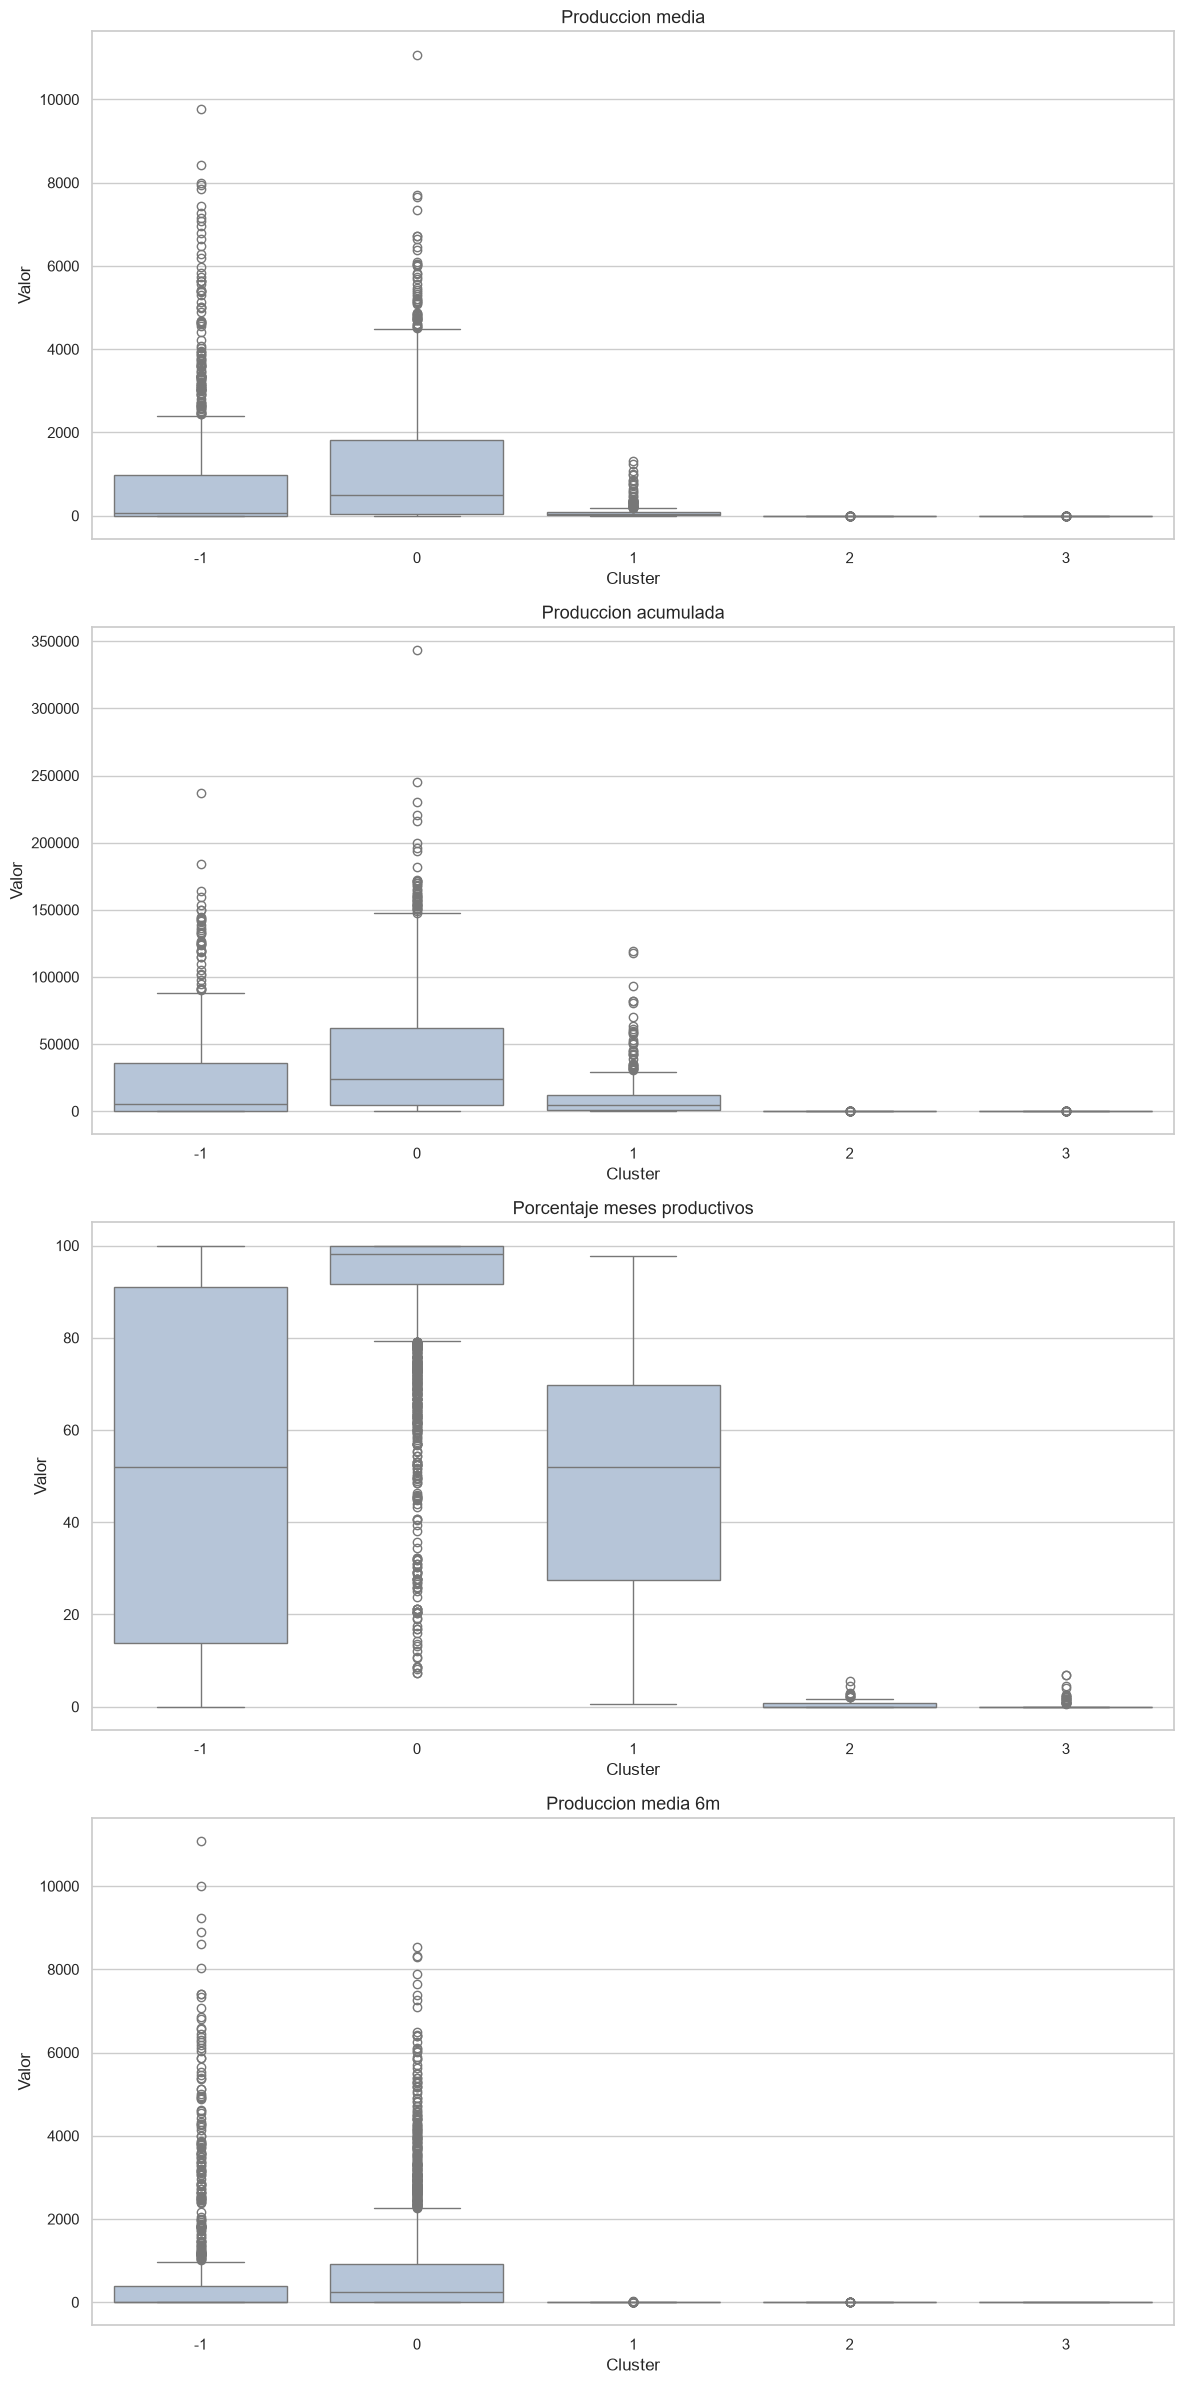

In [55]:
variables_graficos_clusters = [
    "produccion_media",
    "produccion_acumulada",
    "porcentaje_meses_productivos",
    "produccion_media_6m",
]

fig, ejes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(12, 24)
)

for eje, variable in zip(ejes, variables_graficos_clusters):
    sns.boxplot(
        data=perfiles_candidato,
        x="cluster",
        y=variable,
        color="lightsteelblue",
        ax=eje,
    )

    eje.set_title(
        variable.replace("_", " ").capitalize(),
        fontsize=13,
    )
    eje.set_xlabel("Cluster")
    eje.set_ylabel("Valor")

plt.tight_layout()
plt.show()

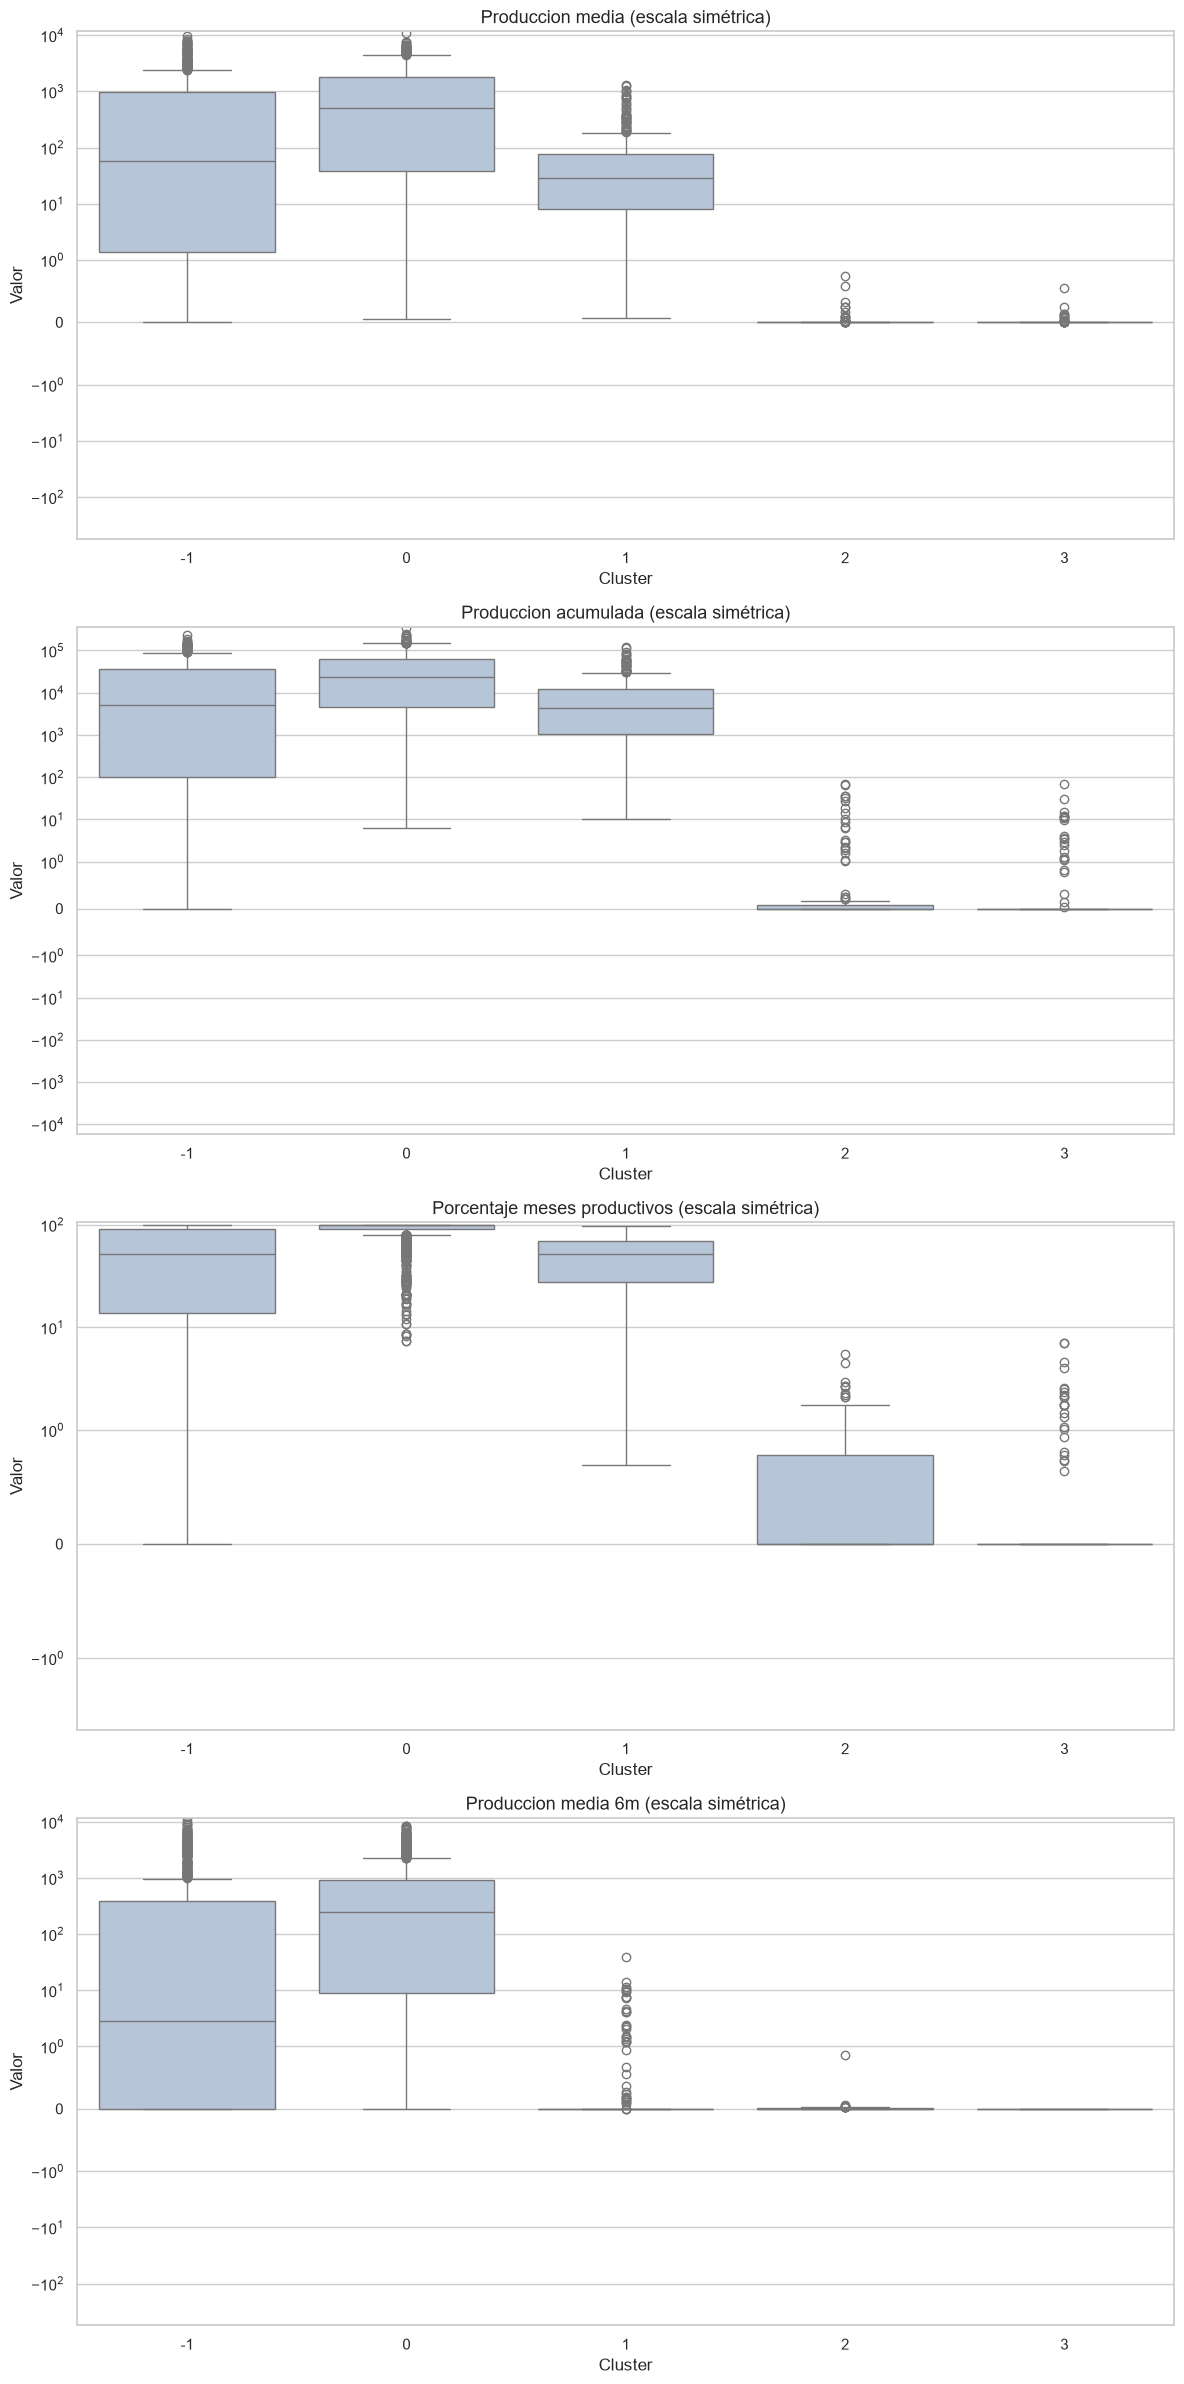

In [56]:
fig, ejes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(12, 24)
)

for eje, variable in zip(ejes, variables_graficos_clusters):
    sns.boxplot(
        data=perfiles_candidato,
        x="cluster",
        y=variable,
        color="lightsteelblue",
        ax=eje,
    )

    eje.set_yscale("symlog", linthresh=1)
    eje.set_title(
        f"{variable.replace('_', ' ').capitalize()} "
        "(escala simétrica)",
        fontsize=13,
    )
    eje.set_xlabel("Cluster")
    eje.set_ylabel("Valor")

plt.tight_layout()
plt.show()

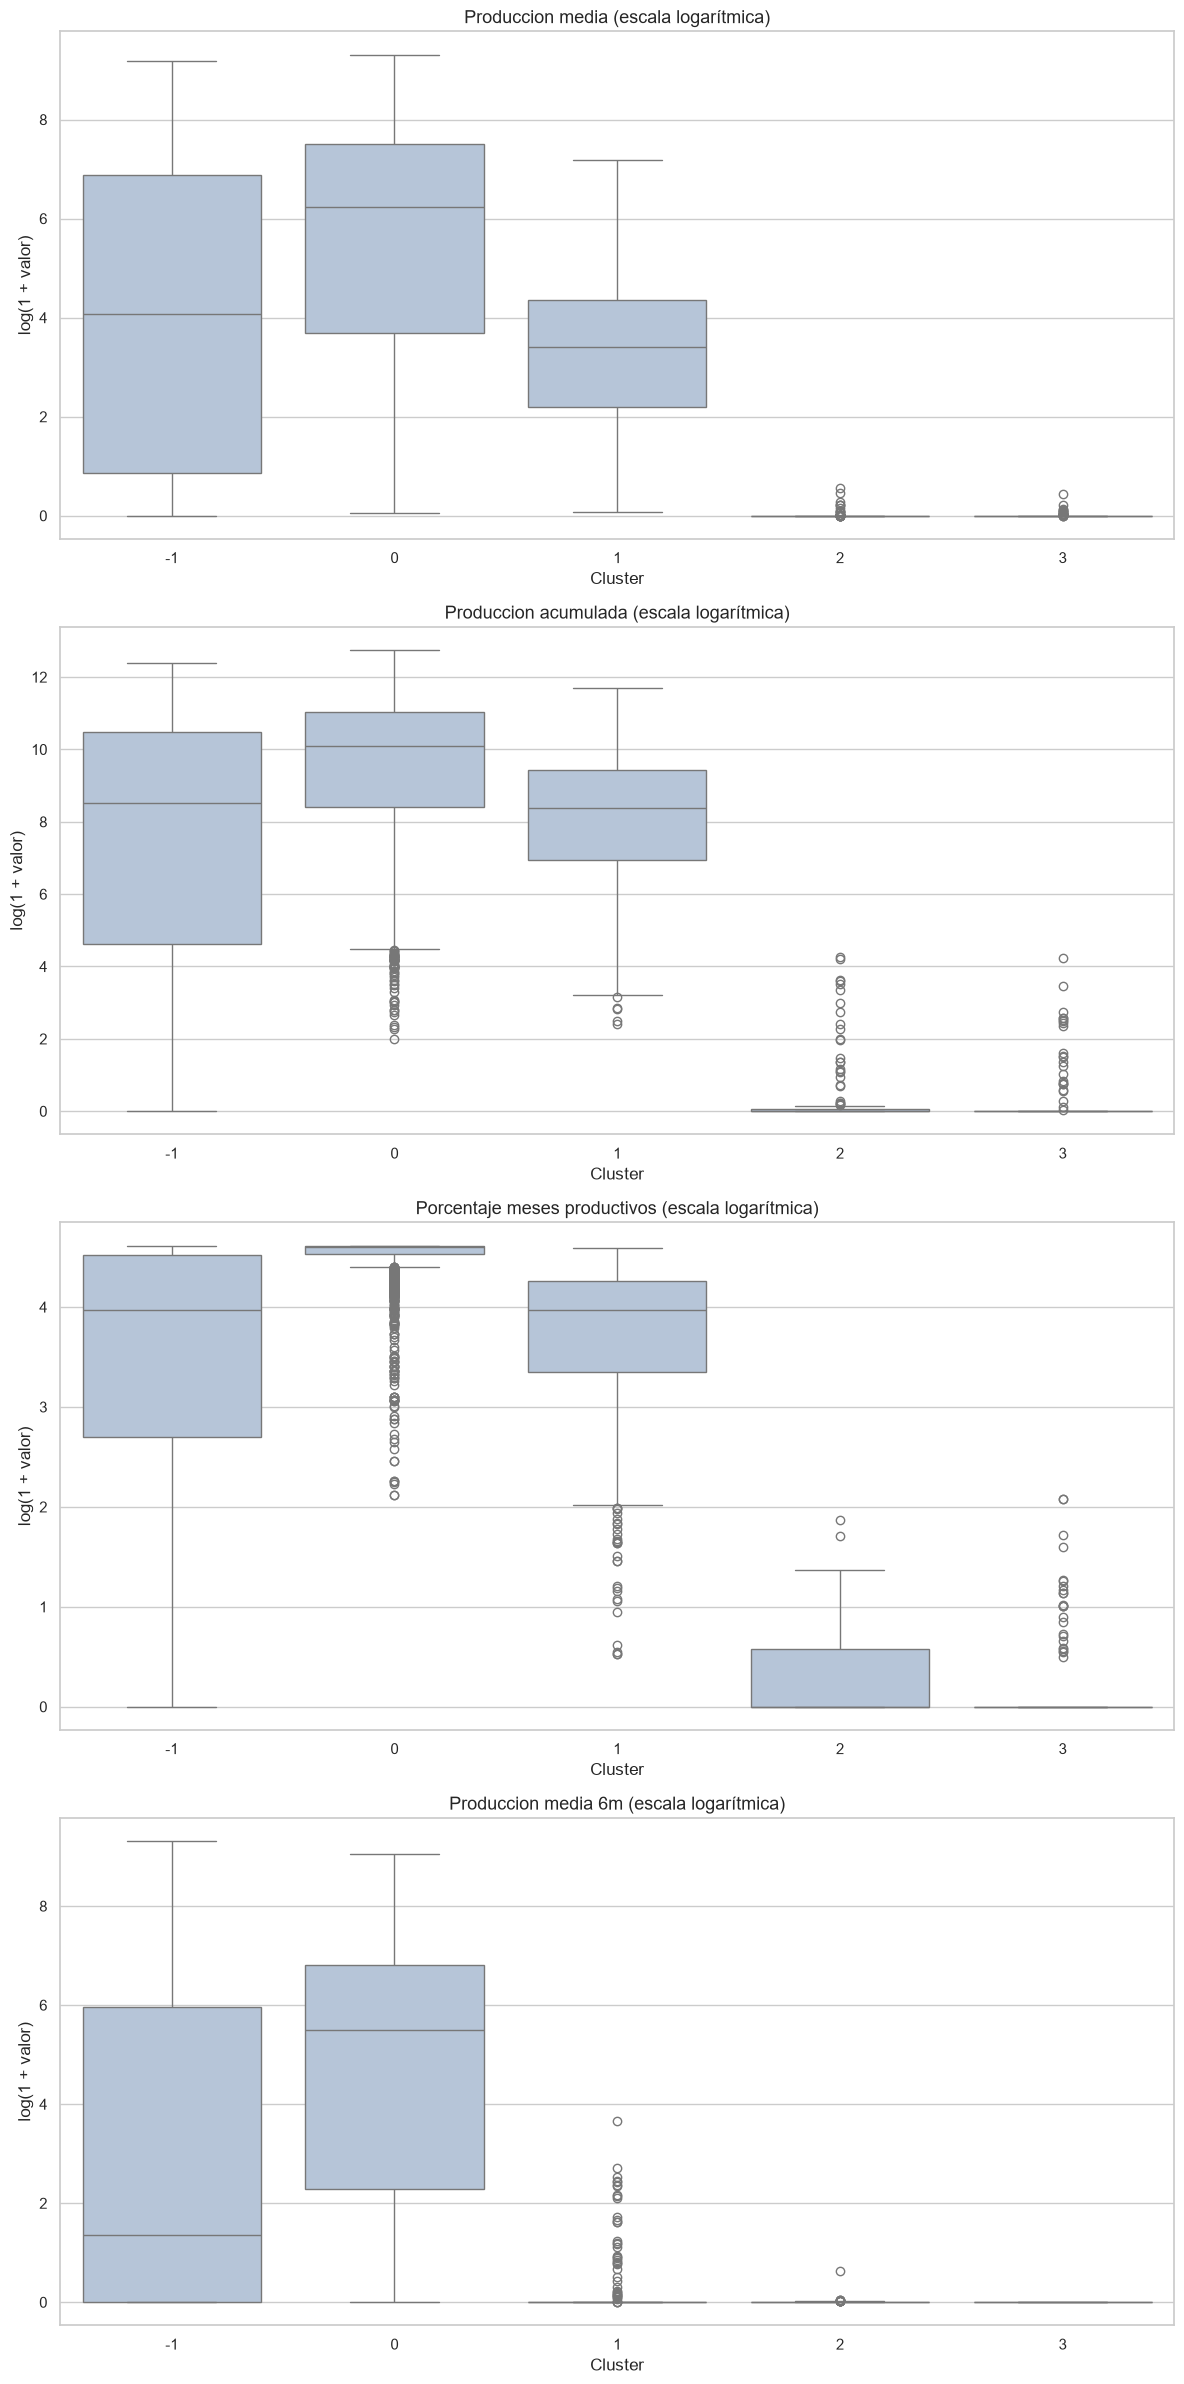

In [57]:
variables_graficos_clusters = [
    "produccion_media",
    "produccion_acumulada",
    "porcentaje_meses_productivos",
    "produccion_media_6m",
]

perfiles_graficos = perfiles_candidato.copy()

for variable in variables_graficos_clusters:
    perfiles_graficos[f"{variable}_log1p"] = np.log1p(
        perfiles_graficos[variable]
    )

fig, ejes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(12, 24)
)

for eje, variable in zip(ejes, variables_graficos_clusters):
    columna_transformada = f"{variable}_log1p"

    sns.boxplot(
        data=perfiles_graficos,
        x="cluster",
        y=columna_transformada,
        color="lightsteelblue",
        ax=eje,
    )

    eje.set_title(
        f"{variable.replace('_', ' ').capitalize()} "
        "(escala logarítmica)",
        fontsize=13,
    )
    eje.set_xlabel("Cluster")
    eje.set_ylabel("log(1 + valor)")

plt.tight_layout()
plt.show()

Los gráficos muestran diferencias claras entre los perfiles obtenidos.

El cluster 0 concentra los pozos con mayor nivel de producción, mayor producción acumulada y una alta proporción de meses productivos.

El cluster 1 presenta una producción histórica menor y un comportamiento reciente prácticamente nulo, aunque sus pozos cuentan con una trayectoria relativamente extensa.

Los clusters 2 y 3 se caracterizan por niveles de producción prácticamente nulos y una proporción muy baja de meses productivos. La diferencia entre ambos deberá analizarse con variables físicas, operativas y categóricas.

Los pozos clasificados como ruido (`-1`) presentan una mayor dispersión y no forman una zona densa suficientemente homogénea. Por ese motivo no se interpretan como un grupo productivo único.